# Практика 5 — Дообучение предобученной сети
## Beans: болезни листьев фасоли

**Assignment 4** · Азиз Абдулин · повтор практики курса по fine-tuning на новом датасете.

В практике 4 ResNet-18 была замороженным извлекателем признаков. Здесь её веса **обновляются** на снимках листьев.
Четыре стратегии, от наименее к наиболее адаптированной:

| Стратегия | Что обучается | Шаг обучения |
|---|---|---|
| A. Линейный классификатор с аугментацией | только новый слой классификации | 1e-3 |
| B. Частичное дообучение | последний остаточный блок (`layer4`) + новый слой | 1e-4 / 1e-3 |
| C. Полное дообучение | все слои | 1e-4 для сети, 1e-3 для нового слоя |
| D. Полное дообучение без аугментации | все слои, без аугментации | как в C — показывает вклад аугментации |

**Общие настройки:** вход 224×224, батч 32, 12 эпох, AdamW (weight decay 1e-4), кросс-энтропия со сглаживанием меток 0,1,
косинусное снижение шага после одной эпохи разогрева; сохраняется эпоха с лучшей точностью на validation.
Аугментация: случайное кадрирование с масштабом (0,6–1), горизонтальные и вертикальные отражения, поворот ±15°,
изменение цвета.

In [1]:
import io, json, math, time, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as Fn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from a4_metrics import accuracy, macro_f1, confusion, bootstrap_ci

SEED = 42
DEV = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
DATA, FIG, RES = Path("data"), Path("figures"), Path("results")
URL = "https://huggingface.co/api/datasets/AI-Lab-Makerere/beans/parquet/default/{}/0.parquet"
split = {}
for s in ("train", "validation", "test"):
    f = DATA / f"beans_{s}.parquet"
    if not f.exists(): urllib.request.urlretrieve(URL.format(s), f)
    d = pd.read_parquet(f)
    split[s] = ([Image.open(io.BytesIO(b["bytes"])).convert("RGB") for b in d.image], d.labels.to_numpy())
CLASSES = ["angular leaf spot", "bean rust", "healthy"]
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
tf_aug = T.Compose([T.RandomResizedCrop(224, scale=(0.6, 1.0)), T.RandomHorizontalFlip(), T.RandomVerticalFlip(), T.RandomRotation(15),
                    T.ColorJitter(0.2, 0.2, 0.2), T.ToTensor(), T.Normalize(MEAN, STD)])
tf_plain = T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor(), T.Normalize(MEAN, STD)])

class Leaves(Dataset):
    def __init__(self, imgs, ys, tf): self.imgs, self.ys, self.tf = imgs, ys, tf
    def __len__(self): return len(self.ys)
    def __getitem__(self, i): return self.tf(self.imgs[i]), int(self.ys[i])

val_dl = DataLoader(Leaves(*split["validation"], tf_plain), batch_size=64)
test_dl = DataLoader(Leaves(*split["test"], tf_plain), batch_size=64)
def evaluate(model, loader):
    model.eval(); preds, ys = [], []
    with torch.no_grad():
        for x, y in loader: preds.append(model(x.to(DEV)).argmax(1).cpu()); ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(preds).numpy()
print("device:", DEV)

device: mps


## 1. Одна функция обучения для всех стратегий

In [2]:
def resnet(trainable):
    m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    m.fc = nn.Linear(512, 3)
    for name, p in m.named_parameters():
        p.requires_grad = trainable == "all" or name.startswith("fc") or (trainable == "layer4" and name.startswith("layer4"))
    return m.to(DEV)

def fine_tune(trainable, augment=True, epochs=12, lr_head=1e-3, lr_body=1e-4):
    torch.manual_seed(SEED)
    m = resnet(trainable)
    head = [p for n, p in m.named_parameters() if n.startswith("fc")]
    body = [p for n, p in m.named_parameters() if p.requires_grad and not n.startswith("fc")]
    groups = [{"params": head, "lr": lr_head}] + ([{"params": body, "lr": lr_body}] if body else [])
    opt = torch.optim.AdamW(groups, weight_decay=1e-4)
    tl = DataLoader(Leaves(*split["train"], tf_aug if augment else tf_plain), batch_size=32, shuffle=True)
    steps, warm = epochs * len(tl), len(tl)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / (steps - warm))))
    hist, best, state, t0 = [], -1, None, time.time()
    for ep in range(epochs):
        m.train()
        if trainable != "all":                                          # frozen BatchNorm layers keep ImageNet statistics
            for mod in m.modules():
                if isinstance(mod, nn.BatchNorm2d) and not any(p.requires_grad for p in mod.parameters()): mod.eval()
        tot = 0
        for x, y in tl:
            x, y = x.to(DEV), y.to(DEV); loss = Fn.cross_entropy(m(x), y, label_smoothing=0.1)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step(); tot += loss.item() * len(y)
        acc = accuracy(*evaluate(m, val_dl)); hist.append({"epoch": ep + 1, "train loss": tot / len(tl.dataset), "val accuracy": acc})
        if acc > best: best, state = acc, {k: v.detach().clone() for k, v in m.state_dict().items()}
    m.load_state_dict(state)
    n_train = sum(p.numel() for p in m.parameters() if p.requires_grad)
    return m, pd.DataFrame(hist), n_train, time.time() - t0

## 2. Обучение четырёх стратегий

In [3]:
STRATS = {"A. linear probe + aug": dict(trainable="head"), "B. fine-tune layer4": dict(trainable="layer4"),
          "C. full fine-tune": dict(trainable="all"), "D. full fine-tune, no aug": dict(trainable="all", augment=False)}
runs = {}
for name, kw in STRATS.items():
    m, h, n, sec = fine_tune(**kw)
    runs[name] = {"model": m, "hist": h, "trainable": n, "seconds": sec}
    print(f"{name:28s} trainable {n:>10,} weights, {sec / 60:.1f} min, best val accuracy {h['val accuracy'].max():.3f} (epoch {int(h.loc[h['val accuracy'].idxmax(), 'epoch'])})")

A. linear probe + aug        trainable      1,539 weights, 0.9 min, best val accuracy 0.835 (epoch 2)


B. fine-tune layer4          trainable  8,395,267 weights, 1.3 min, best val accuracy 0.977 (epoch 10)


C. full fine-tune            trainable 11,178,051 weights, 2.9 min, best val accuracy 1.000 (epoch 6)


D. full fine-tune, no aug    trainable 11,178,051 weights, 2.6 min, best val accuracy 0.992 (epoch 9)


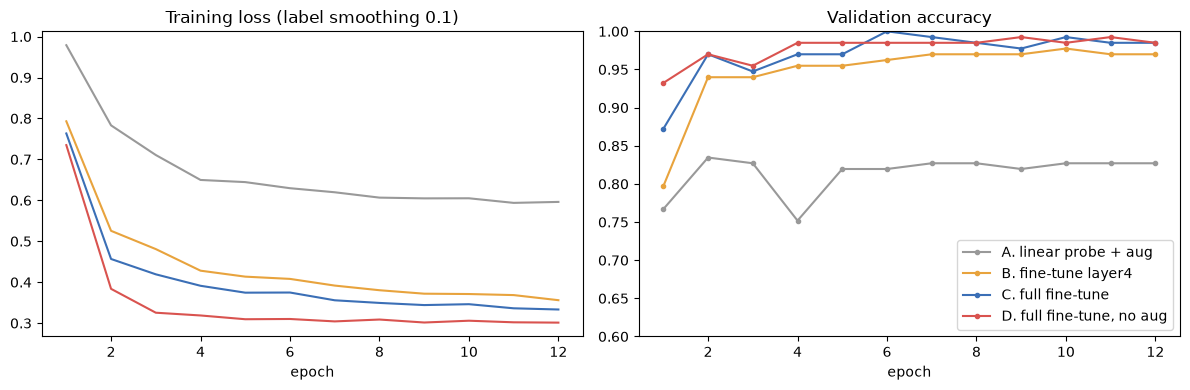

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for (name, r), c in zip(runs.items(), ["#999999", "#e8a33d", "#3b6fb6", "#d9534f"]):
    ax[0].plot(r["hist"]["epoch"], r["hist"]["train loss"], color=c, label=name)
    ax[1].plot(r["hist"]["epoch"], r["hist"]["val accuracy"], color=c, label=name, marker="o", ms=3)
ax[0].set(title="Training loss (label smoothing 0.1)", xlabel="epoch"); ax[1].set(title="Validation accuracy", xlabel="epoch", ylim=(0.6, 1.0))
ax[1].legend(loc="lower right"); plt.tight_layout(); plt.savefig(FIG / "p5_curves.png", dpi=110); plt.show()

## 3. Результаты на test

In [5]:
y_test = split["test"][1]; rows, preds = {}, {}
p4 = json.load(open(RES / "p4_summary.json"))["test"] if (RES / "p4_summary.json").exists() else {}
for k in ["CNN from scratch", "ResNet-18 frozen + linear"]:
    if k in p4: rows[f"(P4) {k}"] = {"trainable weights": "—", "minutes": "—", "test accuracy": p4[k]["accuracy"], "95 % CI": "", "macro-F1": p4[k]["macro_f1"]}
for name, r in runs.items():
    p = evaluate(r["model"], test_dl)[1]; preds[name] = p; lo, hi = bootstrap_ci(y_test, p, accuracy)
    rows[name] = {"trainable weights": f"{r['trainable']:,}", "minutes": round(r["seconds"] / 60, 1), "test accuracy": accuracy(y_test, p),
                  "95 % CI": f"[{lo:.3f}, {hi:.3f}]", "macro-F1": macro_f1(y_test, p, 3)}
res = pd.DataFrame(rows).T
res.to_csv(RES / "p5_test.csv"); res

,trainable weights,minutes,test accuracy,95 % CI,macro-F1
(P4) CNN from scratch,—,—,0.898438,,0.896955
(P4) ResNet-18 frozen + linear,—,—,0.898438,,0.899482
A. linear probe + aug,"1,539",0.9,0.765625,"[0.688, 0.836]",0.767514
B. fine-tune layer4,"8,395,267",1.3,0.96875,"[0.938, 0.992]",0.968986
C. full fine-tune,"11,178,051",2.9,0.960938,"[0.930, 0.992]",0.961219
"D. full fine-tune, no aug","11,178,051",2.6,0.953125,"[0.914, 0.984]",0.953215


При 128 изображениях в test одно изображение — это 0,8 процентного пункта, поэтому 95 %-интервалы широкие: разница в 2–3
пункта — в пределах шума. Кривые на validation (ещё 133 изображения) показывают то же направление.

## 4. Куда смотрит дообученная сеть — Grad-CAM

Grad-CAM взвешивает карты признаков последнего свёрточного блока (`layer4`) градиентом предсказанного класса и показывает,
где на изображении находятся основания для предсказания.

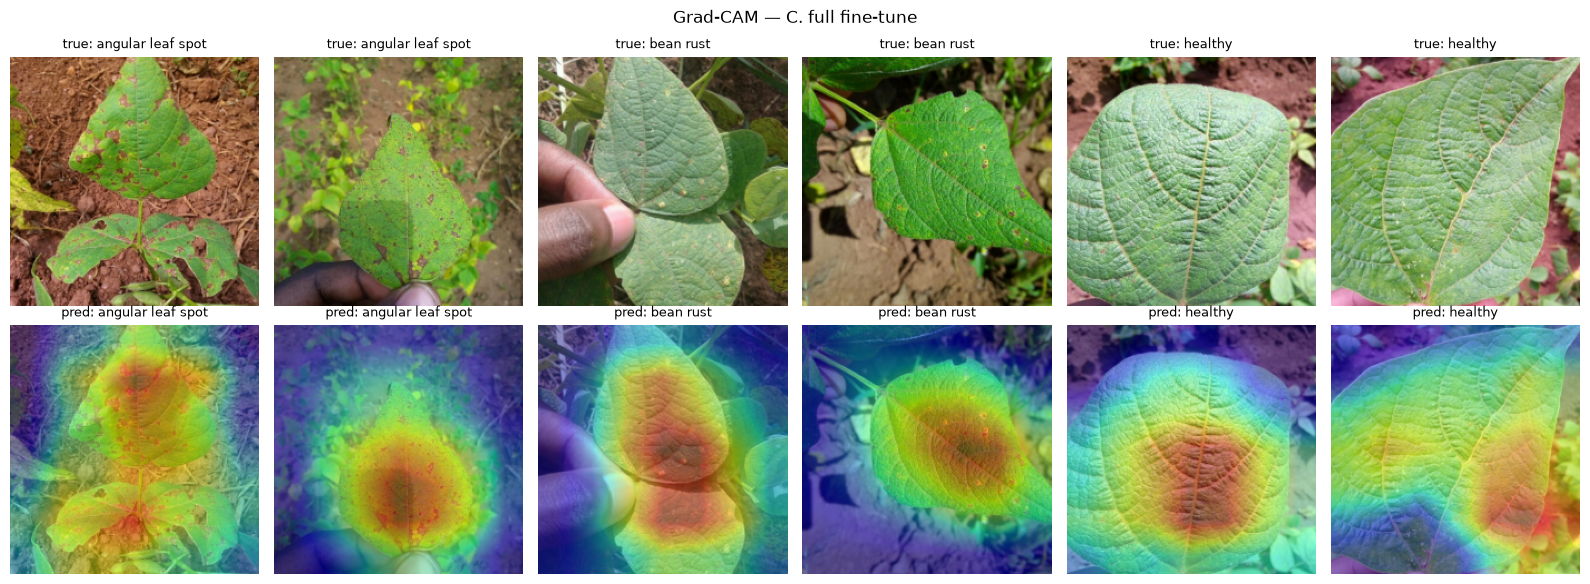

In [6]:
best_name = max(runs, key=lambda k: runs[k]["hist"]["val accuracy"].max()); net = runs[best_name]["model"].eval()
acts, grads = {}, {}
h1 = net.layer4.register_forward_hook(lambda m, i, o: acts.__setitem__("a", o))
h2 = net.layer4.register_full_backward_hook(lambda m, gi, go: grads.__setitem__("g", go[0]))
def gradcam(img):
    x = tf_plain(img).unsqueeze(0).to(DEV).requires_grad_(True)
    out = net(x); c = out.argmax(1).item(); net.zero_grad(); out[0, c].backward()
    w = grads["g"].mean((2, 3), keepdim=True); cam = Fn.relu((w * acts["a"]).sum(1, keepdim=True))
    cam = Fn.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)[0, 0].detach().cpu().numpy()
    return c, (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
imgs = split["test"][0]; pick = [int(np.where(y_test == c)[0][j]) for c in range(3) for j in (0, 1)]
fig, ax = plt.subplots(2, 6, figsize=(16, 6))
for k, i in enumerate(pick):
    c, cam = gradcam(imgs[i]); base = np.asarray(T.CenterCrop(224)(T.Resize(256)(imgs[i])))
    ax[0, k].imshow(base); ax[0, k].set_title(f"true: {CLASSES[y_test[i]]}", fontsize=9)
    ax[1, k].imshow(base); ax[1, k].imshow(cam, cmap="jet", alpha=.45); ax[1, k].set_title(f"pred: {CLASSES[c]}", fontsize=9)
for a in ax.ravel(): a.axis("off")
h1.remove(); h2.remove()
plt.suptitle(f"Grad-CAM — {best_name}"); plt.tight_layout(); plt.savefig(FIG / "p5_gradcam.png", dpi=100); plt.show()

In [7]:
cm = confusion(y_test, preds[best_name], 3)
print(best_name); print(pd.DataFrame(cm, index=[f"true {c}" for c in CLASSES], columns=[f"pred {c}" for c in CLASSES]))
json.dump({k: {"accuracy": accuracy(y_test, v), "macro_f1": macro_f1(y_test, v, 3), "trainable": runs[k]["trainable"],
               "minutes": runs[k]["seconds"] / 60, "best_val": float(runs[k]["hist"]["val accuracy"].max())} for k, v in preds.items()},
          open(RES / "p5_summary.json", "w"), indent=1)

C. full fine-tune
                        pred angular leaf spot  pred bean rust  pred healthy
true angular leaf spot                      42               1             0
true bean rust                               2              41             0
true healthy                                 0               2            40


## 5. Выводы

1. **Дообучение явно лучше замороженной сети.** Обновление весов поднимает точность на test с 89,8 % (замороженная ResNet-18
   + линейный слой, практика 4) до 96,1 % (полное дообучение) и 96,9 % (только `layer4` + голова): ошибок на test становится
   4–5 вместо 13. Validation согласна (100 % и 97,7 %).
2. **Частичного дообучения достаточно.** Обучение последнего остаточного блока (8,4 млн весов, 1,3 мин) не хуже обучения всех
   11,2 млн весов (2,9 мин) — интервалы пересекаются. Ранние слои (края, текстуры) переносятся как есть; последний блок
   подстраивает высокоуровневые признаки под поражения листа.
3. **Аугментация здесь добавляет мало** (96,1 % с ней против 95,3 % без неё — одно изображение test; на validation уровень
   тот же, 98–100 %). Без аугментации потери на train падают ниже всего — сеть плотнее подгоняется под обучающие
   изображения, — но с предобученной сетью, сглаживанием меток и всего 12 эпохами это пока не вредит validation.
4. **Голова, обученная на аугментированных изображениях за 12 эпох, — слабый линейный классификатор** (76,6 %): аугментация
   усложняет задачу для одного слоя, а 12 эпох с небольшим шагом мало. Правильный ориентир «без обновления сети» — линейный
   классификатор из практики 4 на чистых стандартизованных признаках (89,8 %).
5. **Grad-CAM показывает, что сеть смотрит на лист**, где находятся поражения, а не на почву или руку, держащую лист; при
   разрешении последнего блока 7×7 она не может указать на отдельные пустулы. Из 5 оставшихся ошибок полного дообучения
   3 — путаница ржавчины с угловатой пятнистостью и 2 — здоровый лист, принятый за ржавчину.
6. **Сработавшие настройки:** AdamW, разные шаги обучения (1e-4 для сети, 1e-3 для головы), одна эпоха разогрева и
   косинусное снижение, сглаживание меток 0,1, батч 32, лучшая из 12 эпох по точности на validation.